# 01 - Preparação dos Dados para Clustering

Este notebook pega os dados já processados no `00_analítica.ipynb` e os prepara para os algoritmos de clustering.

**Etapas:**
1. Carregar e limpar os dados (mesmo processamento do 00_analítica)
2. Separar features (X) do target (y)
3. Escalonar os dados com StandardScaler
4. Dividir em treino, validação e teste
5. Salvar os dados processados com joblib

## 1. Importações

In [1]:
import pandas as pd
import numpy as np
from joblib import dump, load

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import seaborn as sns

import os

try:
    os.chdir("projeto_hector")
except FileNotFoundError:
    pass

os.listdir("./")

['db',
 'data_report.html',
 '00_analítica.ipynb',
 'data',
 'src',
 '01_preparação_clustering.ipynb',
 '03_classificação.ipynb',
 '02_clustering.ipynb',
 '04_regressão.ipynb']

## 2. Carregar e Processar os Dados

Replicando o processamento do `00_analítica.ipynb` para garantir reprodutibilidade.

In [253]:
# -- LEITURA DO BANCO DE DADOS --

df_followup = pd.read_excel("db/Follow_Up_Dissertação.xlsx", skiprows=[0,1,2,3,4,5])

print(f"Shape original: {df_followup.shape}")
print(f"Colunas: {list(df_followup.columns)}")

Shape original: (221, 55)
Colunas: ['Código', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', ' (AA=1 CA=2 CC=3) ', 'AA=1 CA+CC=2', 'CC=2 AA+CA=1', 'AA= 1 GA=2 GG=3', 'AA=1 GA+GG=2', 'GG=2 AA+GA=1', 'CC=1 TC=2 TT=3', 'CC=1 TC+TT=2', 'TC+CC=1 TT=2', 'TT=1 CT=2 CC=3', 'TT=1 CT+CC=2', 'CC=2 CT+TT=1', 'GG=1 CG=2 CC=3', 'GG=1 CG+CC=2', 'CG+GG=1 CC=2', 'GG=1 CG=2 CC=3.1', 'GG=1 CG+CC=2.1', 'CG+GG=1 CC=1', 'AA=1 GA=2 GG=3', 'AA=1 GA+GG-2', 'GA+AA=1 GG=2', 'AA=1 GA=2 GG=3.1', 'AA=1 GA+GG=2.1', 'GA+AA=1 GG=2.1', 'AA=1 GG=2', 'CC=1 CT=2 TT=3', 'CC=1 CT+TT=2', 'CT+CC=1 TT=2', 'Hormonioterapia N=0 S=1', 'MEDICAMENTO3', 'Data inicial', 'Radioterapia', 'Data inicial2', 'Data final3', 'MEDICAMENTO2', 'Metástase óssea ', 'Orquei', 'Recidiva', 'CPRC', 'novo tumor', 'orgão', 'óbito', 'data Obito', 'motivo do obito', 'Unnamed: 54']


In [254]:
# -- RENOMEAR COLUNAS E REMOVER COLUNAS DESNECESSÁRIAS --

df_followup = df_followup.rename(columns={"Código": "id",
                                          "Unnamed: 1": "GSTP1",
                                          "Unnamed: 4": "MGMT",
                                          "Unnamed: 7": "VDR",
                                          " (AA=1 CA=2 CC=3) ": "BCL2",
                                          "AA= 1 GA=2 GG=3": "CASP9",
                                          "CC=1 TC=2 TT=3": "NKX3",
                                          "TT=1 CT=2 CC=3": "CASP3",
                                          "GG=1 CG=2 CC=3": "PTEN",
                                          "GG=1 CG=2 CC=3.1": "AKT1",
                                          "AA=1 GA=2 GG=3": "PI3K",
                                          "AA=1 GA=2 GG=3.1": "AMACR",
                                          "AA=1 GG=2": "AR",
                                          "CC=1 CT=2 TT=3": "MTOR",
                                          "Recidiva": "cancer_recurrence"})

df_followup = df_followup.drop(df_followup.columns[[2, 3, 5, 6, 8, 9, 11, 12, 14, 15, 17, 18, 20, 21, 23, 24, 26, 27, 29, 30, 32, 33, 36, 37]], axis=1)

print(f"Colunas após renomear: {list(df_followup.columns)}")

Colunas após renomear: ['id', 'GSTP1', 'MGMT', 'VDR', 'BCL2', 'CASP9', 'NKX3', 'CASP3', 'PTEN', 'AKT1', 'PI3K', 'AMACR', 'AR', 'MTOR', 'Hormonioterapia N=0 S=1', 'MEDICAMENTO3', 'Data inicial', 'Radioterapia', 'Data inicial2', 'Data final3', 'MEDICAMENTO2', 'Metástase óssea ', 'Orquei', 'cancer_recurrence', 'CPRC', 'novo tumor', 'orgão', 'óbito', 'data Obito', 'motivo do obito', 'Unnamed: 54']


In [255]:
# -- SUBSTITUIR VALORES INT POR STR (GENÓTIPOS) --

gstp1_dict = {1: "GG", 2: "AG", 3: "AA"}
mgmt_dict = {1: "GG", 2: "AG", 3: "AA"}
vdr_dict = {1: "TT", 2: "TC", 3: "CC"}
bcl2_dict = {1: "AA", 2: "CA", 3: "CC"}
casp9_dict = {1: "AA", 2: "GA", 3: "GG"}
nkx3_dict = {1: "CC", 2: "TC", 3: "TT"}
casp3_dict = {1: "TT", 2: "CT", 3: "CC"}
pten_dict = {1: "GG", 2: "CG", 3: "CC"}
akt1_dict = {1: "GG", 2: "CG", 3: "CC"}
pi3k_dict = {1: "AA", 2: "GA", 3: "GG"}
amacr_dict = {1: "AA", 2: "GA", 3: "GG"}
ar_dict = {1: "AA", 2: "GG"}
mtor_dict = {1: "CC", 2: "CT", 3:"TT"}

gene_dict = {
    "GSTP1": gstp1_dict,
    "MGMT" : mgmt_dict,
    "VDR" : vdr_dict,
    "BCL2": bcl2_dict,
    "CASP9" : casp9_dict,
    "NKX3" : nkx3_dict,
    "CASP3" : casp3_dict,
    "PTEN" : pten_dict,
    "AKT1" : akt1_dict,
    "PI3K" : pi3k_dict,
    "AMACR" : amacr_dict,
    "AR" : ar_dict,
    "MTOR" : mtor_dict
}

for key, value in gene_dict.items():
    if key in df_followup.columns:
        df_followup[key] = df_followup[key].replace(value)

df_followup.head()

,id,GSTP1,MGMT,VDR,BCL2,CASP9,NKX3,CASP3,PTEN,AKT1,...,Metástase óssea,Orquei,cancer_recurrence,CPRC,novo tumor,orgão,óbito,data Obito,motivo do obito,Unnamed: 54
0,Pt 04,AA,AA,TC,CC,GA,TC,CC,CG,CG,...,2.0,NaN,2.0,NaN,NaN,NaN,NaN,NaT,NaN,NaN
1,Pt 09,AG,AA,TC,CA,GA,TC,TT,CG,CC,...,2.0,NaN,2.0,NaN,NaN,NaN,NaN,NaT,NaN,NaN
2,Pt 10,AG,AG,CC,CA,GA,TC,CC,GG,CC,...,1.0,1.0,1.0,1.0,2.0,NaN,1,2007-04-01,NaN,NaN
3,Pt 12,GG,AG,CC,CA,GG,TC,CC,CG,CC,...,2.0,2.0,1.0,NaN,2.0,NaN,1,NaT,NaN,*Ultimo 2014
4,Pt 13,AA,AG,CC,CA,GA,TT,CC,CG,CC,...,2.0,2.0,2.0,NaN,NaN,NaN,2,NaT,NaN,NaN


In [256]:
# -- REMOVER COLUNAS CLÍNICAS (MANTER APENAS GENES + RECIDIVA) --

df_followup = df_followup.drop(df_followup.iloc[:, 14:23], axis=1)
df_followup = df_followup.drop(df_followup.iloc[:, 15:], axis=1)

print(f"Colunas finais: {list(df_followup.columns)}")
df_followup.head()

Colunas finais: ['id', 'GSTP1', 'MGMT', 'VDR', 'BCL2', 'CASP9', 'NKX3', 'CASP3', 'PTEN', 'AKT1', 'PI3K', 'AMACR', 'AR', 'MTOR', 'cancer_recurrence']


,id,GSTP1,MGMT,VDR,BCL2,CASP9,NKX3,CASP3,PTEN,AKT1,PI3K,AMACR,AR,MTOR,cancer_recurrence
0,Pt 04,AA,AA,TC,CC,GA,TC,CC,CG,CG,GA,GG,GG,CT,2.0
1,Pt 09,AG,AA,TC,CA,GA,TC,TT,CG,CC,GG,GA,AA,CT,2.0
2,Pt 10,AG,AG,CC,CA,GA,TC,CC,GG,CC,GA,GG,GG,CC,1.0
3,Pt 12,GG,AG,CC,CA,GG,TC,CC,CG,CC,GA,AA,AA,CT,1.0
4,Pt 13,AA,AG,CC,CA,GA,TT,CC,CG,CC,GG,GA,AA,CT,2.0


In [257]:
# -- LIMPAR IDS E AJUSTAR TARGET --

df_followup["id"] = df_followup["id"].apply(lambda x: x.replace(" ", "").upper())
df_followup["cancer_recurrence"] = df_followup["cancer_recurrence"].replace({2: 0})

# Remover linhas com NaN
print(f"Antes de remover NaN: {df_followup.shape}")
df_followup = df_followup.dropna()
print(f"Depois de remover NaN: {df_followup.shape}")

# Converter target para inteiro
df_followup["cancer_recurrence"] = df_followup["cancer_recurrence"].astype(int)

display(df_followup["cancer_recurrence"].value_counts())
df_followup.head()

Antes de remover NaN: (221, 15)
Depois de remover NaN: (219, 15)


0    110
1    109
Name: cancer_recurrence, dtype: int64

,id,GSTP1,MGMT,VDR,BCL2,CASP9,NKX3,CASP3,PTEN,AKT1,PI3K,AMACR,AR,MTOR,cancer_recurrence
0,PT04,AA,AA,TC,CC,GA,TC,CC,CG,CG,GA,GG,GG,CT,0
1,PT09,AG,AA,TC,CA,GA,TC,TT,CG,CC,GG,GA,AA,CT,0
2,PT10,AG,AG,CC,CA,GA,TC,CC,GG,CC,GA,GG,GG,CC,1
3,PT12,GG,AG,CC,CA,GG,TC,CC,CG,CC,GA,AA,AA,CT,1
4,PT13,AA,AG,CC,CA,GA,TT,CC,CG,CC,GG,GA,AA,CT,0


 ---
#### *AR* apresentou alta correlação em `data_report.html` com *AMACR* \
 Como *AMACR* possui mais genótipos que o *AR* e portanto pode apresentar maior informações sobre a amostra que o *AR* decidimos remover o *AR*

In [258]:
df_followup = df_followup.drop(columns=["AR"])


# Remover do dicionário para evitar erros
gene_dict.pop("AR")
display(df_followup.shape)
df_followup.head()

(219, 14)

,id,GSTP1,MGMT,VDR,BCL2,CASP9,NKX3,CASP3,PTEN,AKT1,PI3K,AMACR,MTOR,cancer_recurrence
0,PT04,AA,AA,TC,CC,GA,TC,CC,CG,CG,GA,GG,CT,0
1,PT09,AG,AA,TC,CA,GA,TC,TT,CG,CC,GG,GA,CT,0
2,PT10,AG,AG,CC,CA,GA,TC,CC,GG,CC,GA,GG,CC,1
3,PT12,GG,AG,CC,CA,GG,TC,CC,CG,CC,GA,AA,CT,1
4,PT13,AA,AG,CC,CA,GA,TT,CC,CG,CC,GG,GA,CT,0


### Subdividindo em grupos de genes de acordo com a significância clínica:

> **Grupo_1**: Enzimas quinases e fosfatases. \
  _PI3K, AKT1, MTOR, PTEN__

>**Grupo_2**: Reguladores de morte celular. \
  _BCL2, CASP9, CASP3_

>**Grupo_3**: Reguladores de transcrição, metabolismo e defesa. \
  _GSTP1, MGMT, AMACR, NKX3, VDR_


### Vamos usar Label Enconding para definir os valores dos genes

In [259]:
# Vamos usar label encoding para definir valores para as categorias de cada gene.
lista_genes = df_followup.columns.drop(["id", "cancer_recurrence"])

df_followup_ids = df_followup.copy()
df_followup_ids = df_followup_ids.drop(columns=lista_genes)

for gene in lista_genes:
    df_followup_ids[gene] = pd.factorize(df_followup[gene])[0]

df_followup_ids["cancer_recurrence"] = df_followup["cancer_recurrence"].copy()
display(df_followup_ids.shape)
df_followup_ids.head()

(219, 14)

,id,cancer_recurrence,GSTP1,MGMT,VDR,BCL2,CASP9,NKX3,CASP3,PTEN,AKT1,PI3K,AMACR,MTOR
0,PT04,0,0,0,0,0,0,0,0,0,0,0,0,0
1,PT09,0,1,0,0,1,0,0,1,0,1,1,1,0
2,PT10,1,1,1,1,1,0,0,0,1,1,0,0,1
3,PT12,1,2,1,1,1,1,0,0,0,1,0,2,0
4,PT13,0,0,1,1,1,0,1,0,0,1,1,1,0


In [260]:
# Agora usanmos os IDs para gerar valores para os grupos que combinam os números dos genes
lista_grupo_1 = ["PI3K", "AKT1", "MTOR", "PTEN"]
lista_grupo_2 = ["BCL2", "CASP9", "CASP3"]
lista_grupo_3 = ["GSTP1", "MGMT", "AMACR", "NKX3", "VDR"]

df_followup_groups = pd.DataFrame()
df_followup_groups["Grupo_1"] = df_followup_ids[lista_grupo_1].sum(axis=1)
df_followup_groups["Grupo_2"] = df_followup_ids[lista_grupo_2].sum(axis=1)
df_followup_groups["Grupo_3"] = df_followup_ids[lista_grupo_3].sum(axis=1)
df_followup_groups["id"] = df_followup["id"].copy()
df_followup_groups["cancer_recurrence"] = df_followup["cancer_recurrence"]

df_followup_groups.head()

,Grupo_1,Grupo_2,Grupo_3,id,cancer_recurrence
0,0,0,0,PT04,0
1,2,2,2,PT09,0
2,3,1,3,PT10,1
3,1,2,6,PT12,1
4,2,1,4,PT13,0


In [ ]:
# Ao invés de ultilizar label encoding e somar que pode confundir genótipos distintos como o mesmo, decidi testar a abordagem de concatenação e geração de frequências

df_followup_groups = df_followup.copy()

df_followup_groups["Grupo_1"] = df_followup[lista_grupo_1].astype(str).agg("".join, axis=1)
df_followup_groups["Grupo_2"] = df_followup[lista_grupo_2].astype(str).agg("".join, axis=1)
df_followup_groups["Grupo_3"] = df_followup[lista_grupo_3].astype(str).agg("".join, axis=1)
df_followup_groups = df_followup_groups.drop(columns=lista_genes)

df_followup_groups.head()

# Nesse caso a ordem importa, portando se atentar a lista de genes e a ordem que foram colocados.

,id,cancer_recurrence,Grupo_1,Grupo_2,Grupo_3
0,PT04,0,GACGCTCG,CCGACC,AAAAGGTCTC
1,PT09,0,GGCCCTCG,CAGATT,AGAAGATCTC
2,PT10,1,GACCCCGG,CAGACC,AGAGGGTCCC
3,PT12,1,GACCCTCG,CAGGCC,GGAGAATCCC
4,PT13,0,GGCCCTCG,CAGACC,AAAGGATTCC


In [264]:
# Tentar transformar os valores dos grupos em frequencias (frequency encoding dos grupos)

lista_grupos = ["Grupo_1", "Grupo_2", "Grupo_3"]

for grupo in lista_grupos:
    freq_percentage = df_followup_groups[grupo].value_counts(normalize=True)
    df_followup_groups[grupo] = df_followup_groups[grupo].map(freq_percentage)

display(df_followup_groups.shape)
df_followup_groups.head()

(219, 5)

,id,cancer_recurrence,Grupo_1,Grupo_2,Grupo_3
0,PT04,0,0.004566,0.105023,0.027397
1,PT09,0,0.009132,0.004566,0.041096
2,PT10,1,0.013699,0.219178,0.009132
3,PT12,1,0.004566,0.091324,0.004566
4,PT13,0,0.009132,0.219178,0.009132


### Outra opção é utilizar Frequency encoding nos genotipos:

In [177]:
# Vamos usar frequency encoding para definir frequencias para as categorias de cada gene.
lista_genes = df_followup.columns.drop(["id", "cancer_recurrence"])

df_followup_freq = df_followup.copy()
df_followup_freq = df_followup_freq.drop(columns=lista_genes)

for gene in lista_genes:
    freq_percentage = df_followup[gene].value_counts(normalize=True) # Normalize aqui é importante para o modelo em Machine Learning
    df_followup_freq[gene] = df_followup[gene].map(freq_percentage)

df_followup_freq["cancer_recurrence"] = df_followup["cancer_recurrence"].copy()
display(df_followup_freq.shape)
df_followup_freq.head()

(219, 14)

,id,cancer_recurrence,GSTP1,MGMT,VDR,BCL2,CASP9,NKX3,CASP3,PTEN,AKT1,PI3K,AMACR,MTOR
0,PT04,0,0.506849,0.826484,0.616438,0.273973,0.511416,0.401826,0.748858,0.429224,0.246575,0.328767,0.388128,0.036530
1,PT09,0,0.369863,0.826484,0.616438,0.515982,0.511416,0.401826,0.018265,0.429224,0.748858,0.625571,0.447489,0.036530
2,PT10,1,0.369863,0.146119,0.383562,0.515982,0.511416,0.401826,0.748858,0.392694,0.748858,0.328767,0.388128,0.086758
3,PT12,1,0.123288,0.146119,0.383562,0.515982,0.219178,0.401826,0.748858,0.429224,0.748858,0.328767,0.164384,0.036530
4,PT13,0,0.506849,0.146119,0.383562,0.515982,0.511416,0.484018,0.748858,0.429224,0.748858,0.625571,0.447489,0.036530


In [150]:
# -- ONE-HOT ENCODING DOS GENÓTIPOS --

df_followup = pd.get_dummies(df_followup, columns=gene_dict.keys(), dtype=int)

print(f"Shape final com dummies: {df_followup.shape}")
display(df_followup.head())

Shape final com dummies: (219, 37)


,id,cancer_recurrence,GSTP1_AA,GSTP1_AG,GSTP1_GG,MGMT_AA,MGMT_AG,MGMT_GG,VDR_CC,VDR_TC,...,AKT1_GG,PI3K_AA,PI3K_GA,PI3K_GG,AMACR_AA,AMACR_GA,AMACR_GG,MTOR_CC,MTOR_CT,MTOR_TT
0,PT04,0,1,0,0,1,0,0,0,1,...,0,0,1,0,0,0,1,0,1,0
1,PT09,0,0,1,0,1,0,0,0,1,...,0,0,0,1,0,1,0,0,1,0
2,PT10,1,0,1,0,0,1,0,1,0,...,0,0,1,0,0,0,1,1,0,0
3,PT12,1,0,0,1,0,1,0,1,0,...,0,0,1,0,1,0,0,0,1,0
4,PT13,0,1,0,0,0,1,0,1,0,...,0,0,0,1,0,1,0,0,1,0


#### Selecionar features com maiores informações para cada genes

Para a análise bivariada posterior, é necessário selecionar 1 feature para cada gene que fornece a maior quantidade de informações. 
Para isso usamos a soma dos index para cada genótipo.

> Isso será usado no **clustering**

In [99]:
lista_genes = df_followup.columns.drop(["id", "cancer_recurrence"])

soma_genes = df_followup[lista_genes].sum()

soma_genes.sort_values(ascending=False).head(15)

MTOR_TT     192
MGMT_AA     181
AKT1_CC     164
CASP3_CC    164
PI3K_GG     137
VDR_TC      135
BCL2_CA     113
CASP9_GA    112
GSTP1_AA    111
NKX3_TT     106
AMACR_GA     98
PTEN_CG      94
NKX3_TC      88
PTEN_GG      86
AMACR_GG     85
dtype: int64

## 3. Separar Features e Target

Para clustering, trabalhamos principalmente com as features (X). O target (`cancer_recurrence`) será usado para **avaliar** a qualidade dos clusters, não para treiná-los.

In [265]:
# Adaptar dados para usar os grupos
df_followup = df_followup_groups.copy()

#Adaptar dados para usar as frequencias
#df_followup = df_followup_freq.copy()

# Separar features e target
X = df_followup.drop(columns=["id", "cancer_recurrence"]) # Features
y = df_followup["cancer_recurrence"] # Target

print(f"Features (X) shape: {X.shape}")
print(f"Target (y) shape: {y.shape}")
print(f"\nFeatures: {list(X.columns)}")
print(f"\nDistribuição do target:\n{y.value_counts()}")

Features (X) shape: (219, 3)
Target (y) shape: (219,)

Features: ['Grupo_1', 'Grupo_2', 'Grupo_3']

Distribuição do target:
0    110
1    109
Name: cancer_recurrence, dtype: int64


## 4. Escalonamento dos Dados (StandardScaler)

O escalonamento é **essencial** para algoritmos baseados em distância (K-Means, DBSCAN, Agglomerative). Embora os dados já sejam binários (0/1), o StandardScaler garante que nenhuma feature domine o cálculo de distância.

> **Nota:** O professor usou `StandardScaler` — mantemos a mesma abordagem.

In [266]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"X_scaled shape: {X_scaled.shape}")
print(f"Média de cada feature (deve ser ~0): {X_scaled.mean(axis=0).round(2)[:5]}...")
print(f"Std de cada feature (deve ser ~1): {X_scaled.std(axis=0).round(2)[:5]}...")

X_scaled shape: (219, 3)
Média de cada feature (deve ser ~0): [ 0. -0.  0.]...
Std de cada feature (deve ser ~1): [1. 1. 1.]...


## 5. Divisão em Treino, Validação e Teste

Seguindo, dividimos em:
- **Treino (60%)**: Para ajustar os modelos e fazer cross-validation
- **Validação (20%)**: Para testar a consistência dos clusters
- **Teste (20%)**: Para avaliação final

In [ ]:
# Primeiro split: 80% treino+valid, 20% teste
X_temp, X_test, y_temp, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

# Segundo split: 75% treino, 25% validação (de 80% = 60% e 20% do total)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp
)

print(f"X_train shape: {X_train.shape}")
print(f"X_valid shape: {X_valid.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"\ny_train distribution:\n{pd.Series(y_train).value_counts()}")
print(f"\ny_valid distribution:\n{pd.Series(y_valid).value_counts()}")
print(f"\ny_test distribution:\n{pd.Series(y_test).value_counts()}")

X_train shape: (131, 3)
X_valid shape: (44, 3)
X_test shape:  (44, 3)

y_train distribution:
0    66
1    65
Name: cancer_recurrence, dtype: int64

y_valid distribution:
1    22
0    22
Name: cancer_recurrence, dtype: int64

y_test distribution:
1    22
0    22
Name: cancer_recurrence, dtype: int64


## 6. Salvar os Dados Processados

Salvamos tudo com `joblib` para reusar no notebook de clustering.

In [268]:
# Salvar datasets
dump(X_train, "data/01_X_train")
dump(X_valid, "data/01_X_valid")
dump(X_test, "data/01_X_test")
dump(y_train, "data/01_y_train")
dump(y_valid, "data/01_y_valid")
dump(y_test, "data/01_y_test")

# Salvar também o scaler e os nomes das features
dump(scaler, "data/01_scaler")
dump(list(X.columns), "data/01_feature_names")

# Salvar o DataFrame completo processado
dump(df_followup, "data/01_df_processado")

print("✅ Dados salvos com sucesso!")
print(f"Arquivos em data/: {os.listdir('data')}")

✅ Dados salvos com sucesso!
Arquivos em data/: ['01_y_train', '01_X_test', '02_best_params_dbscan', '02_best_params_agg', '02_comparacao_clustering', '01_X_train', '02_comparacao_algoritmos', '01_scaler', '02_best_params_kmeans', '01_df_processado', '01_y_test', '02_resultados_agg', '01_feature_names', '02_resultados_kmeans', '01_y_valid', '01_X_valid', '02_resultados_dbscan']


## 7. Visualização Exploratória (PCA)

Como temos 37 features, não conseguimos plotar diretamente. Usamos **PCA** (Análise de Componentes Principais) para projetar os dados em 2D e visualizar padrões.

Variância explicada pelas 2 componentes: 68.53%


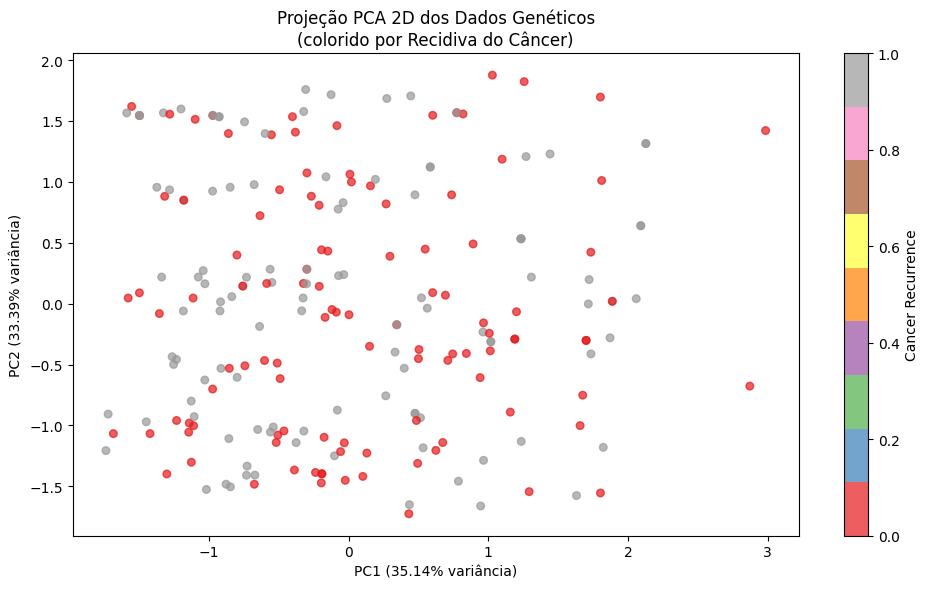

In [269]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(f"Variância explicada pelas 2 componentes: {pca.explained_variance_ratio_.sum():.2%}")

plt.figure(figsize=(10, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='Set1', s=30, alpha=0.7)
plt.colorbar(scatter, label='Cancer Recurrence')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variância)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variância)')
plt.title('Projeção PCA 2D dos Dados Genéticos\n(colorido por Recidiva do Câncer)')
plt.tight_layout()
plt.show()